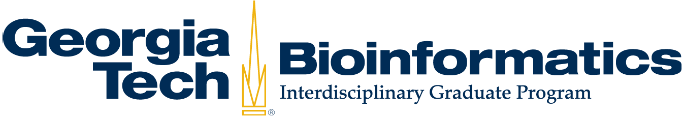

<div class="alert alert-block alert-info">
    <h1>BIOS 4150/BIOL 6150</h1>
    <h3>Instructor: Dr. King Jordan</h3>
    <p>Nilavrah Sensarma (nsensarma3@gatech.edu)</p>
    <p>Valli Sree Lasya Pasumarthy (vpasumarthy3@gatech.edu)

</p>
</div>

<div class="alert alert-block alert-warning">
    <h2>Project 8 (Pharmacogenomics) starter notebook</h2>
    <h3>Deadline: 11:59PM, November 17th, 2025</h3>
</div>

<div class="alert alert-block alert-danger">
    <h2>Alert!</h2>
    <p>Do not delete any comments or information boxes the starter notebook comes with</p>
</div>

---

# **1. Knowing your data**
### *Total Questions: 3*
### *Total Points: 5+5+20 = 30*


---

<div class="alert alert-block alert-warning">
    <h3>1.1 Download the information file</h3>
    <p>For this project, you will need to access PharmGKB annotated variants. PharmGKB has multiple resources, but we will focus on the clinical variant data file. This file should have variant-drug pairs and level of evidence for all clinical annotations.</p>
    <p>Download the file and show top 5 lines of the file</p>
</div>

In [6]:
#Show the file here.
!head -n 6 ./clinicalVariants.tsv

variant	gene	type	level of evidence	chemicals	phenotypes
CYP2C9*1, CYP2C9*3, CYP2C9*13	CYP2C9	Metabolism/PK	1A	lornoxicam	
rs17376848	DPYD	Toxicity	1A	capecitabine	Neoplasms
rs2297595	DPYD	Toxicity	1A	capecitabine	Neoplasms
rs1801265	DPYD	Toxicity	1A	capecitabine	Neoplasms
CYP2C19*1, CYP2C19*2, CYP2C19*3	CYP2C19	Metabolism/PK	1A	dexlansoprazole	


<div class="alert alert-block alert-warning">
    <h3>1.2 Filter the file</h3>
    <p>Although star alleles can be processed, we will only focus on dbSNP annotated variants (those that have rs ids)</p>
    <p>Filter the file for dbSNP annotated variants and count them</p>
    
</div>

In [17]:
# wc -l after filtering
import pandas as pd

df = pd.read_csv("./clinicalVariants.tsv", sep="\t", dtype=str)

# First line filters for 'rs' variants, second line filters for all others so I can validate
rs_df = df[df["variant"].str.startswith("rs", na=False)]
not_rs_df = df[~df["variant"].str.startswith("rs", na=False)]


# print(len(df))
print(len(rs_df)) # Prints the number of dbSNP annotated variants identified by an id starting with 'rs'
# print(len(not_rs_df))
# print(rs_df)
# print(not_rs_df)

# Outputting to a tsv file, but you can also use the rs_df directly if you're using python below
rs_df.to_csv("filtered_clinical_variants.tsv", sep="\t", index=False)

4593


<div class="alert alert-block alert-warning">
    <h3>1.3 Think ahead!</h3>
    <p><b>Eventual Goal:</b> Quantify the presence of the variants obtained in Question 1.2. We will extract these variants from the 1000 genomes VCF file.</p>
    <p>Use whatever resource you want to. The end goal is to have appropriate information about these variants obtained in 1.2.</p>
    <p>If you have to subset a VCF file (extract variants of interest), you will need information such as CHR, POS, etc. Although you can simply use the ID column to extract variants, that might not work everywhere.</p>
    <p>If you want to use R, please feel free to do so. Add screenshots from PACE-ICE RStudio here. Your R workflow would essentially output a nice tsv file which you use later to extract variants</p>
    
</div>

<div class="alert alert-block alert-danger">
    <h2>Alert!</h2>
    <p>We do not want you to use dbSNP IDs (rs ids) to extract variants from the 1000 genomes data. The 1000 genomes file we provided you has dbSNP IDs and a simple bcftools command will do the job. But most VCF files you will come across in your work will not have dbSNP IDs. Therefore, we expect you to find relevant information about the variants obtained in Question 1.2 before moving to section 2.</p>
</div>

### Step 1.3.1: Identify unique pharmacogenomic variants:

We extracted unique dbSNP identifiers (rsIDs) from the filtered PharmGKB clinical variant dataset. Since multiple clinical annotation rows can refer to the same genetic variant, we identified the distinct rsIDs before retrieving their genomic coordinates. These unique identifiers serve as the input for the coordinate lookup.

In [ ]:
import pandas as pd
import os
import gzip

# Load filtered PharmGKB data
variants = pd.read_csv(
    "filtered_clinical_variants.tsv",
    sep="\t"
)

# Extract unique dbSNP identifiers
unique_rsids = variants["variant"].dropna().astype(str).unique()

# Display summary statistics
print("Total PharmGKB annotation rows:", len(variants))
print("Total unique dbSNP variants:", len(unique_rsids))
print(
    "Additional annotation rows beyond unique rsIDs:",
    len(variants) - len(unique_rsids)
)

# Display the first 10 unique variants
print("\nFirst 10 unique variants:")
print(unique_rsids[:10])

Total PharmGKB annotation rows: 4593
Total unique dbSNP variants: 2845
Additional annotation rows beyond unique rsIDs: 1748

First 10 unique variants:
['rs17376848' 'rs2297595' 'rs1801265' 'rs1801160' 'rs1801159' 'rs1801158'
 'rs2108622' 'rs121434568' 'rs9923231' 'rs116855232']


### Step 1.3.2: Identify the genome assembly:

Before retrieving genomic coordinates, we identified the reference genome assembly used by the 1000 Genomes VCF file. This is important because genomic positions differ between reference assemblies. We inspected the VCF header to confirm that the provided data uses GRCh38, allowing us to retrieve coordinates from the same assembly.

In [ ]:
# Define the chromosome 1 VCF file
vcf_path = (
    "/storage/ice-shared/biol6150/Data2/1000Genomes/"
    "phase3.chr1.GRCh38.GT.crossmap.vcf.gz"
)

# Confirm that the VCF file is accessible
print("VCF exists:", os.path.exists(vcf_path))

# Inspect the VCF header for the reference assembly
with gzip.open(vcf_path, "rt") as f:
    for line in f:
        if line.startswith("##contig=<ID=1,"):
            print("\nChromosome 1 contig information:")
            print(line.strip())

        if line.startswith("#CHROM"):
            print("\nVCF column header:")
            print(line.strip())
            break

VCF exists: True

Chromosome 1 contig information:
##contig=<ID=1,length=248956422,assembly=GRCh38_full_analysis_set_plus_decoy_hla.fa>

VCF column header:
#CHROM	POS	ID	REF	ALT	QUAL	FILTER	INFO	FORMAT	HG00096	HG00097	HG00099	HG00100	HG00101	HG00102	HG00103	HG00105	HG00106	HG00107	HG00108	HG00109	HG00110	HG00111	HG00112	HG00113	HG00114	HG00115	HG00116	HG00117	HG00118	HG00119	HG00120	HG00121	HG00122	HG00123	HG00125	HG00126	HG00127	HG00128	HG00129	HG00130	HG00131	HG00132	HG00133	HG00136	HG00137	HG00138	HG00139	HG00140	HG00141	HG00142	HG00143	HG00145	HG00146	HG00148	HG00149	HG00150	HG00151	HG00154	HG00155	HG00157	HG00158	HG00159	HG00160	HG00171	HG00173	HG00174	HG00176	HG00177	HG00178	HG00179	HG00180	HG00181	HG00182	HG00183	HG00185	HG00186	HG00187	HG00188	HG00189	HG00190	HG00231	HG00232	HG00233	HG00234	HG00235	HG00236	HG00237	HG00238	HG00239	HG00240	HG00242	HG00243	HG00244	HG00245	HG00246	HG00250	HG00251	HG00252	HG00253	HG00254	HG00255	HG00256	HG00257	HG00258	HG00259	HG00260	HG00261	HG0026

### Step 1.3.3: Retrieve genomic coordinates for unique variants:

We used the NCBI Variation Services API to retrieve genomic information for the unique dbSNP identifiers identified in Step 1.3.1. We selected placements from the GRCh38.p14 reference assembly and restricted the results to primary chromosomes, excluding alternate and patch sequences.

For each qualifying placement, we extracted the chromosome, genomic position, reference sequence, and alternate sequence using the SPDI representation. We converted the zero-based SPDI position to a one-based coordinate. Multiple alternate alleles were retained as separate records.

Empty deleted or inserted sequences were preserved because they can represent valid insertions or deletions in SPDI format. These indel representations may require reference-based anchoring and normalization before direct comparison with VCF alleles.

The resulting table provides genomic coordinate and allele information for the pharmacogenomic variants, allowing us to identify candidate variants in the 1000 Genomes data without relying solely on rsIDs.

In [ ]:
import requests
import time

# NCBI RefSNP API endpoint
base_url = "https://api.ncbi.nlm.nih.gov/variation/v0/refsnp/"

# GRCh38 primary chromosome RefSeq accessions
refseq_to_chr = {
    "NC_000001.11": "1",
    "NC_000002.12": "2",
    "NC_000003.12": "3",
    "NC_000004.12": "4",
    "NC_000005.10": "5",
    "NC_000006.12": "6",
    "NC_000007.14": "7",
    "NC_000008.11": "8",
    "NC_000009.12": "9",
    "NC_000010.11": "10",
    "NC_000011.10": "11",
    "NC_000012.12": "12",
    "NC_000013.11": "13",
    "NC_000014.9": "14",
    "NC_000015.10": "15",
    "NC_000016.10": "16",
    "NC_000017.11": "17",
    "NC_000018.10": "18",
    "NC_000019.10": "19",
    "NC_000020.11": "20",
    "NC_000021.9": "21",
    "NC_000022.11": "22",
    "NC_000023.11": "X",
    "NC_000024.10": "Y",
    "NC_012920.1": "MT"
}

print("Primary chromosome accessions:", len(refseq_to_chr))

Primary chromosome accessions: 25


In [ ]:
def extract_grch38_coordinates(record, rsid):

    coordinate_records = []

    placements = record.get(
        "primary_snapshot_data", {}
    ).get("placements_with_allele", [])

    for placement in placements:

        annotation = placement.get("placement_annot", {})
        traits = annotation.get("seq_id_traits_by_assembly", [])

        # Select GRCh38.p14 primary chromosome placements
        is_grch38_primary = any(
            trait.get("assembly_accession") == "GCF_000001405.40"
            and trait.get("is_chromosome") is True
            and trait.get("is_top_level") is True
            and not trait.get("is_alt")
            and not trait.get("is_patch")
            for trait in traits
        )

        seq_id = placement.get("seq_id")
        chromosome = refseq_to_chr.get(seq_id)

        if not is_grch38_primary or chromosome is None:
            continue

        for allele_record in placement.get("alleles", []):

            spdi = allele_record.get("allele", {}).get("spdi")

            if not spdi or spdi.get("seq_id") != seq_id:
                continue

            ref = spdi.get("deleted_sequence")
            alt = spdi.get("inserted_sequence")

            # Exclude missing or reference-identical alleles
            if ref is None or alt is None or ref == alt:
                continue

            # Convert zero-based SPDI position to one-based position
            pos = int(spdi["position"]) + 1

            coordinate_records.append({
                "rsID": rsid,
                "CHR": chromosome,
                "POS": pos,
                "END": pos + len(ref) - 1,
                "REF": ref,
                "ALT": alt,
                "ASSEMBLY": "GRCh38.p14"
            })

    return coordinate_records

In [ ]:
# Test the NCBI API using rs699
test_response = requests.get(
    base_url + "699",
    headers={"Accept": "application/json"},
    timeout=30
)

print("Status code:", test_response.status_code)

test_response.raise_for_status()

test_data = test_response.json()

print("Returned rsID:", test_data["refsnp_id"])

# Extract GRCh38 coordinates for rs699
test_coordinates = extract_grch38_coordinates(
    test_data,
    "rs699"
)

test_df = pd.DataFrame(test_coordinates)

display(test_df)

Status code: 200
Returned rsID: 699


,rsID,CHR,POS,END,REF,ALT,ASSEMBLY
0,rs699,1,230710048,230710048,A,C,GRCh38.p14
1,rs699,1,230710048,230710048,A,G,GRCh38.p14
2,rs699,1,230710048,230710048,A,T,GRCh38.p14


In [ ]:
# NCBI GRCh38 coordinate output files
coordinate_file = "pharmacogenomic_variant_coordinates_NCBI_GRCh38.tsv"
status_file = "rsid_lookup_status_NCBI_GRCh38.tsv"

# Start with clean results
coordinate_rows = []
status_by_rsid = {}

coordinate_columns = [
    "rsID", "CHR", "POS", "END", "REF", "ALT", "ASSEMBLY"
]

# Save progress to disk
def save_checkpoint():

    coordinate_df = pd.DataFrame(
        coordinate_rows,
        columns=coordinate_columns
    ).drop_duplicates()

    coordinate_df.to_csv(
        coordinate_file,
        sep="\t",
        index=False
    )

    status_output = pd.DataFrame(
        list(status_by_rsid.items()),
        columns=["rsID", "status"]
    )

    status_output.to_csv(
        status_file,
        sep="\t",
        index=False
    )


# Create an HTTP session
session = requests.Session()
session.headers.update({"Accept": "application/json"})

# API request settings
max_retries = 4
checkpoint_interval = 25

completed_this_run = 0

# Retrieve each unique rsID
for i, rsid in enumerate(unique_rsids, start=1):

    rsid = str(rsid)

    # Skip IDs successfully processed in an earlier run
    previous_status = status_by_rsid.get(rsid)

    if previous_status in [
        "mapped",
        "no_GRCh38_primary_mapping",
        "not_found_in_NCBI"
    ]:
        continue

    numeric_id = rsid.removeprefix("rs")
    url = base_url + numeric_id

    record = None
    not_found = False

    # Retry failed requests
    for attempt in range(max_retries):

        try:
            response = session.get(url, timeout=(10, 30))

            # Respect NCBI request rate
            time.sleep(1.05)

            if response.status_code == 404:
                not_found = True
                break

            response.raise_for_status()

            record = response.json()
            break

        except (requests.exceptions.RequestException, ValueError) as error:

            print(
                f"{rsid}: attempt {attempt + 1} failed: {error}",
                flush=True
            )

            if attempt < max_retries - 1:
                time.sleep(5 * (attempt + 1))

    # Record identifiers that do not exist in NCBI
    if not_found:

        status_by_rsid[rsid] = "not_found_in_NCBI"

    # Keep unsuccessful requests separate for later retry
    elif record is None:

        status_by_rsid[rsid] = "failed"

    else:

        # Extract qualifying GRCh38 coordinates
        new_records = extract_grch38_coordinates(record, rsid)

        if new_records:

            coordinate_rows.extend(new_records)
            status_by_rsid[rsid] = "mapped"

        else:

            status_by_rsid[rsid] = "no_GRCh38_primary_mapping"

    completed_this_run += 1

    # Save progress periodically
    if completed_this_run % checkpoint_interval == 0:

        save_checkpoint()

        print(
            f"Processed this run: {completed_this_run} "
            f"| Mapped rsIDs: {sum(v == 'mapped' for v in status_by_rsid.values())} "
            f"| Failed: {sum(v == 'failed' for v in status_by_rsid.values())}",
            flush=True
        )

# Save final checkpoint
save_checkpoint()

print("\nNCBI retrieval finished.")
print("Total unique input rsIDs:", len(unique_rsids))
print("Mapped rsIDs:", sum(v == "mapped" for v in status_by_rsid.values()))
print(
    "No GRCh38 primary mapping:",
    sum(v == "no_GRCh38_primary_mapping" for v in status_by_rsid.values())
)
print(
    "Not found in NCBI:",
    sum(v == "not_found_in_NCBI" for v in status_by_rsid.values())
)
print("Failed requests:", sum(v == "failed" for v in status_by_rsid.values()))

Processed this run: 25 | Mapped rsIDs: 25 | Failed: 0
Processed this run: 50 | Mapped rsIDs: 50 | Failed: 0
Processed this run: 75 | Mapped rsIDs: 75 | Failed: 0
Processed this run: 100 | Mapped rsIDs: 100 | Failed: 0
Processed this run: 125 | Mapped rsIDs: 125 | Failed: 0
Processed this run: 150 | Mapped rsIDs: 150 | Failed: 0
Processed this run: 175 | Mapped rsIDs: 175 | Failed: 0
Processed this run: 200 | Mapped rsIDs: 200 | Failed: 0
Processed this run: 225 | Mapped rsIDs: 225 | Failed: 0
Processed this run: 250 | Mapped rsIDs: 250 | Failed: 0
Processed this run: 275 | Mapped rsIDs: 275 | Failed: 0
Processed this run: 300 | Mapped rsIDs: 300 | Failed: 0
Processed this run: 325 | Mapped rsIDs: 325 | Failed: 0
Processed this run: 350 | Mapped rsIDs: 349 | Failed: 0
Processed this run: 375 | Mapped rsIDs: 374 | Failed: 0
Processed this run: 400 | Mapped rsIDs: 399 | Failed: 0
Processed this run: 425 | Mapped rsIDs: 424 | Failed: 0
Processed this run: 450 | Mapped rsIDs: 448 | Failed: 

### Step 1.3.4: Validate genomic coordinates:

After retrieving genomic coordinates, we performed quality-control checks to evaluate the completeness and consistency of the coordinate dataset.

We compared the original set of unique rsIDs with the identifiers recorded in the NCBI lookup-status file and the coordinate table. We also examined the lookup outcomes, checked for missing values and duplicate records, and confirmed the genome assembly.

Multiple coordinate records were retained when an rsID had multiple alternate alleles. Empty deleted or inserted sequences were preserved because they represent valid SPDI allele representations for certain insertions and deletions, rather than missing data.

The validated coordinate table and a separate file containing records with empty SPDI allele sequences were saved for subsequent analysis.

In [ ]:

# ==========================================
# SECTION 1.3.4: VALIDATE GENOMIC COORDINATES
# ==========================================

# Load the NCBI GRCh38 coordinate and status files
# Preserve empty SPDI allele sequences as empty strings

coordinates = pd.read_csv(
    "pharmacogenomic_variant_coordinates_NCBI_GRCh38.tsv",
    sep="\t",
    dtype=str,
    keep_default_na=False
)

lookup_status = pd.read_csv(
    "rsid_lookup_status_NCBI_GRCh38.tsv",
    sep="\t",
    dtype=str,
    keep_default_na=False
)

# ------------------------------------------
# 1. Compare input and mapped identifiers
# ------------------------------------------

input_rsids = set(map(str, unique_rsids))
mapped_rsids = set(coordinates["rsID"])
status_rsids = set(lookup_status["rsID"])

print("SECTION 1.3.4: COORDINATE VALIDATION")
print("------------------------------------")

print("Unique input rsIDs:", len(input_rsids))
print("Unique mapped rsIDs:", len(mapped_rsids))
print("Total coordinate records:", len(coordinates))

# ------------------------------------------
# 2. Check NCBI lookup status
# ------------------------------------------

status_counts = lookup_status["status"].value_counts()

print("\nLookup status:")
print(status_counts)

unaccounted_rsids = input_rsids - status_rsids

print(
    "\nInput rsIDs without a recorded status:",
    len(unaccounted_rsids)
)

# Compare mapped IDs with coordinate records
status_mapped = set(
    lookup_status.loc[
        lookup_status["status"] == "mapped",
        "rsID"
    ]
)

missing_coordinate_rsids = status_mapped - mapped_rsids
unexpected_coordinate_rsids = mapped_rsids - status_mapped

print(
    "\nMapped IDs missing from coordinate file:",
    len(missing_coordinate_rsids)
)

print(
    "Coordinate IDs not marked as mapped:",
    len(unexpected_coordinate_rsids)
)

# ------------------------------------------
# 3. Check missing values
# ------------------------------------------

print("\nMissing values:")

print(
    coordinates[
        ["rsID", "CHR", "POS", "END", "REF", "ALT", "ASSEMBLY"]
    ].isna().sum()
)

# ------------------------------------------
# 4. Inspect empty SPDI allele sequences
# ------------------------------------------

empty_ref_records = coordinates[
    coordinates["REF"] == ""
]

empty_alt_records = coordinates[
    coordinates["ALT"] == ""
]

empty_allele_records = coordinates[
    (coordinates["REF"] == "") |
    (coordinates["ALT"] == "")
].copy()

print("\nEmpty SPDI allele sequences:")
print("Empty REF sequences:", len(empty_ref_records))
print("Empty ALT sequences:", len(empty_alt_records))

print(
    "Records with empty SPDI allele sequences:",
    len(empty_allele_records)
)

print(
    "Affected unique rsIDs:",
    empty_allele_records["rsID"].nunique()
)

# Save empty-allele records for quality-control review
empty_allele_records.to_csv(
    "pharmacogenomic_variants_missing_alleles_review.tsv",
    sep="\t",
    index=False
)

print("\nSaved empty-allele review file.")

# ------------------------------------------
# 5. Check duplicate records
# ------------------------------------------

duplicate_count = coordinates.duplicated().sum()

print("\nDuplicate coordinate records:", duplicate_count)

# ------------------------------------------
# 6. Confirm genome assembly
# ------------------------------------------

print("\nGenome assembly:")
print(coordinates["ASSEMBLY"].value_counts())

# ------------------------------------------
# 7. Check data consistency
# ------------------------------------------

assert len(unaccounted_rsids) == 0, (
    "Some input rsIDs have no lookup status."
)

assert len(missing_coordinate_rsids) == 0, (
    "Some mapped rsIDs are missing from the coordinate file."
)

assert len(unexpected_coordinate_rsids) == 0, (
    "Some coordinate rsIDs are not marked as mapped."
)

assert duplicate_count == 0, (
    "Duplicate coordinate records were found."
)

assert coordinates["ASSEMBLY"].eq("GRCh38.p14").all(), (
    "Unexpected genome assembly found."
)

# ------------------------------------------
# 8. Save validated coordinate table
# ------------------------------------------

validated_file = (
    "pharmacogenomic_variant_coordinates_NCBI_GRCh38_validated.tsv"
)

coordinates.to_csv(
    validated_file,
    sep="\t",
    index=False
)

print("\nValidated coordinate file saved:", validated_file)

# Display first 10 coordinate records
display(coordinates.head(10))


SECTION 1.3.4: COORDINATE VALIDATION
------------------------------------
Unique input rsIDs: 2845
Unique mapped rsIDs: 2841
Total coordinate records: 5665

Lookup status:
status
mapped                       2841
no_GRCh38_primary_mapping       4
Name: count, dtype: int64

Input rsIDs without a recorded status: 0

Mapped IDs missing from coordinate file: 0
Coordinate IDs not marked as mapped: 0

Missing values:
rsID        0
CHR         0
POS         0
END         0
REF         0
ALT         0
ASSEMBLY    0
dtype: int64

Empty SPDI allele sequences:
Empty REF sequences: 24
Empty ALT sequences: 5
Records with empty SPDI allele sequences: 29
Affected unique rsIDs: 10

Saved empty-allele review file.

Duplicate coordinate records: 0

Genome assembly:
ASSEMBLY
GRCh38.p14    5665
Name: count, dtype: int64

Validated coordinate file saved: pharmacogenomic_variant_coordinates_NCBI_GRCh38_validated.tsv


,rsID,CHR,POS,END,REF,ALT,ASSEMBLY
0,rs17376848,1,97450068,97450068,A,G,GRCh38.p14
1,rs2297595,1,97699535,97699535,T,A,GRCh38.p14
2,rs2297595,1,97699535,97699535,T,C,GRCh38.p14
3,rs1801265,1,97883329,97883329,A,C,GRCh38.p14
4,rs1801265,1,97883329,97883329,A,G,GRCh38.p14
5,rs1801265,1,97883329,97883329,A,T,GRCh38.p14
6,rs1801160,1,97305364,97305364,C,A,GRCh38.p14
7,rs1801160,1,97305364,97305364,C,G,GRCh38.p14
8,rs1801160,1,97305364,97305364,C,T,GRCh38.p14
9,rs1801159,1,97515839,97515839,T,A,GRCh38.p14


# **2. Extract data**
### *Total Questions: 2*
### *Total Points: 5+15=20*


---

<div class="alert alert-block alert-warning">
    <h3>2.1 Subset the VCF files</h3>
    <p>2.1.1 How many variants obtained in 1.2 were found in the 1000 genomes data?</p>
    <p>2.1.2 Subset the VCF files (all chromosomes) and write the number of Pharmacogenomic variants found in chromosome 2.</p>
</div>

In [46]:
import subprocess, shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

src_dir = Path.home() / "biol6150/Data2/1000Genomes"
scratch_dir = Path.home() / "scratch/1000Genomes"
scratch_dir.mkdir(parents=True, exist_ok=True)

def prep(chrom):
    name = f"phase3.chr{chrom}.GRCh38.GT.crossmap.vcf.gz"
    vcf = scratch_dir / name
    if not vcf.exists():
        shutil.copy(src_dir / name, vcf)
    has_idx = Path(str(vcf) + ".csi").exists() or Path(str(vcf) + ".tbi").exists()
    if not has_idx:
        subprocess.run(["bcftools", "index", "-c", str(vcf)], check=True)
        return f"chr{chrom}: indexed"
    return f"chr{chrom}: already indexed"

with ThreadPoolExecutor(max_workers=4) as ex:
    for msg in ex.map(prep, range(1, 23)):
        print(msg, flush=True)

chr1: already indexed
chr2: indexed
chr3: indexed
chr4: indexed
chr5: indexed
chr6: already indexed
chr7: already indexed
chr8: already indexed
chr9: already indexed
chr10: already indexed
chr11: already indexed
chr12: already indexed
chr13: already indexed
chr14: already indexed
chr15: already indexed
chr16: already indexed
chr17: already indexed
chr18: already indexed
chr19: already indexed
chr20: already indexed
chr21: already indexed
chr22: already indexed


In [48]:
missing = []
for chrom in range(1, 23):
    vcf = scratch_dir / f"phase3.chr{chrom}.GRCh38.GT.crossmap.vcf.gz"
    if not (Path(str(vcf) + ".csi").exists() or Path(str(vcf) + ".tbi").exists()):
        missing.append(chrom)
print("Missing indexes:", missing)   # want []

Missing indexes: []


In [49]:
test_vcf = scratch_dir / "phase3.chr2.GRCh38.GT.crossmap.vcf.gz"
out = subprocess.run(["bcftools", "index", "-s", str(test_vcf)],
                     capture_output=True, text=True, check=True).stdout
vcf_chr_name = out.split()[0]
print("VCF chromosome name:", vcf_chr_name)
use_chr = vcf_chr_name.startswith("chr")

VCF chromosome name: chr2


In [50]:
regions = pd.read_csv("pharmacogenomic_regions.tsv", sep="\t", header=None,
                      names=["CHR", "POS"], dtype={"CHR": str})
regions["CHR"] = "chr" + regions["CHR"].str.removeprefix("chr")

regions.to_csv("pharmacogenomic_regions_vcf.tsv", sep="\t", index=False, header=False)
print("Genomic positions:", len(regions))
regions.head()

Genomic positions: 2792


,CHR,POS
0,chr1,97450190
1,chr13,48045719
2,chr1,97515839
3,chr7,117559591
4,chr1,97573943


2.1.2 Subset the VCF files (all chromosomes) and write the number of Pharmacogenomic variants found in chromosome 2

In [51]:
output_dir = Path("subset_vcfs")
output_dir.mkdir(exist_ok=True)

for chrom in range(1, 23):
    input_vcf = scratch_dir / f"phase3.chr{chrom}.GRCh38.GT.crossmap.vcf.gz"
    output_vcf = output_dir / f"chr{chrom}_subset.vcf.gz"

    subprocess.run(["bcftools", "view", "-R", "pharmacogenomic_regions_vcf.tsv",
                    "-Oz", "-o", str(output_vcf), str(input_vcf)], check=True)
    subprocess.run(["bcftools", "index", "-t", str(output_vcf)], check=True)

    n = subprocess.run(["bcftools", "view", "-H", str(output_vcf)],
                       capture_output=True, text=True, check=True).stdout.count("\n")
    print(f"chr{chrom}: {n} records", flush=True)

chr1: 261 records
chr2: 183 records
chr3: 131 records
chr4: 143 records
chr5: 114 records
chr6: 274 records
chr7: 157 records
chr8: 77 records
chr9: 98 records
chr10: 140 records
chr11: 136 records
chr12: 150 records
chr13: 49 records
chr14: 48 records
chr15: 85 records
chr16: 121 records
chr17: 83 records
chr18: 33 records
chr19: 143 records
chr20: 50 records
chr21: 37 records
chr22: 54 records


In [52]:
!bcftools view -H subset_vcfs/chr2_subset.vcf.gz | wc -l

183


In [75]:
rows = []
for chrom in range(1, 23):
    f = output_dir / f"chr{chrom}_subset.vcf.gz"
    out = subprocess.run(["bcftools", "query", "-f", "%CHROM\t%POS\t%ID\t%REF\t%ALT\n", str(f)],
                         capture_output=True, text=True, check=True).stdout
    rows += [l.split("\t") for l in out.splitlines()]

found = pd.DataFrame(rows, columns=["CHR", "POS", "VCF_ID", "REF", "ALT"])
found["CHR"] = found["CHR"].str.removeprefix("chr")
found["POS"] = found["POS"].astype(int)
print("Total VCF records:", len(found))

Total VCF records: 2567


In [76]:
m = coordinates_df.merge(found, on=["CHR", "POS"], how="inner")

def alleles_ok(r):
    ens = set(r["allele_string"].split("/"))
    return r["REF"] in ens and any(a in ens for a in r["ALT"].split(","))

m["allele_match"] = m.apply(alleles_ok, axis=1)

print("Variants matched by position:", m["variant"].nunique())
print("Variants matched by position + alleles:", m.loc[m.allele_match, "variant"].nunique())   # 2.1.1 answer

final = m[m["allele_match"]].drop_duplicates(subset=["variant", "CHR", "POS", "REF", "ALT"])
final.to_csv("pgx_found_variants.tsv", sep="\t", index=False)
print(final.shape, final["variant"].nunique())

Variants matched by position: 2530
Variants matched by position + alleles: 2530
(2542, 9) 2530


# **3. Pharmacogenomic variant distribution in 1000 genomes populations**
### *Total Steps: 3*
### *Total Points:  25+5+20=50*


---

<div class="alert alert-block alert-warning">
    <h3>3.1 Distribution by populations</h3>
        <p>For the 26 populations present in the 1000 genomes data, show the distribution of pharmaocgenomic variant frequencies stratified by "level of evidence"</p><hr>
    <h4>Step 1 - Find variant frequencies for all pharmacogenomic variants within each population.</h4>
    <p>The end result of this step should be a TSV file which has <i>x rows and 26 + w columns</i>. x = number of pharmacogenomic variants found in 1000 genome VCF files. 26 columns represent each 1000 genome population. w will be additonal metadata about the pharmacogenomic variant such as CHR POS ID etc</p>
    <p>This is a good exercise to implement a nice bash or python based solution where you can streamline a lot of things.</p>
    <h4>Step 2 - Annotate variants by level of evidence</h4>
    <p>This should be easy, just annotate them in your code or create separate files.</p>
    <h4>Step 3 - Visualize using boxplots</h4>
    <p>Every level of evidence will have it's set of 26 box plots showing frequency distribution of all variants </p>
    <p>In the end you will have multiple box plot graphs like the one shown below. Each graph will correspond to a specific level of evidence as determined by PharmaGKB (1A, 1B, 2A, 2B, ... , etc)</p>
</div>

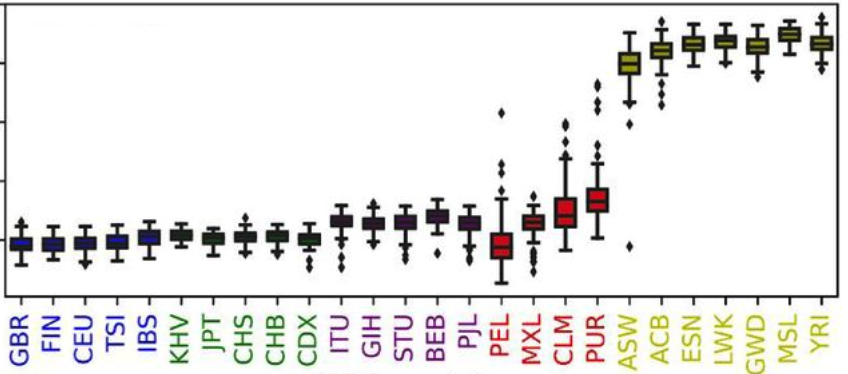

Here we download the 1000 Genomes sample panel. And it maps each of the 2,504 samples to its population (26 total) and super-population (5 total), which we need to group genotypes by population.

In [57]:
!wget -O ~/biol6150/ProjectSubmissions/Group4/Project8/integrated_call_samples_v3.20130502.ALL.panel \
  https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/integrated_call_samples_v3.20130502.ALL.panel
!head -3 ~/biol6150/ProjectSubmissions/Group4/Project8/integrated_call_samples_v3.20130502.ALL.panel
!wc -l ~/biol6150/ProjectSubmissions/Group4/Project8/integrated_call_samples_v3.20130502.ALL.panel

--2026-11-23 17:59:12--  https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/integrated_call_samples_v3.20130502.ALL.panel
Resolving ftp.1000genomes.ebi.ac.uk (ftp.1000genomes.ebi.ac.uk)... 193.62.193.167
Connecting to ftp.1000genomes.ebi.ac.uk (ftp.1000genomes.ebi.ac.uk)|193.62.193.167|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 55156 (54K)
Saving to: ‘/home/hice1/cechcharef3/biol6150/ProjectSubmissions/Group4/Project8/integrated_call_samples_v3.20130502.ALL.panel’

/home/hice1/cechcha 100%[===================>]  53.86K   294KB/s    in 0.2s    

2026-11-23 17:59:13 (294 KB/s) - ‘/home/hice1/cechcharef3/biol6150/ProjectSubmissions/Group4/Project8/integrated_call_samples_v3.20130502.ALL.panel’ saved [55156/55156]

sample	pop	super_pop	gender		
HG00096	GBR	EUR	male
HG00097	GBR	EUR	female
2505 /home/hice1/cechcharef3/biol6150/ProjectSubmissions/Group4/Project8/integrated_call_samples_v3.20130502.ALL.panel


In [70]:

import subprocess, io, numpy as np, pandas as pd
from pathlib import Path


shared_directory = Path.home() / "biol6150/ProjectSubmissions/Group4/Project8"
panel_file = shared_directory / "integrated_call_samples_v3.20130502.ALL.panel"   

panel = pd.read_csv(panel_file, sep="\t")[["sample", "pop"]]

output_dir = Path("subset_vcfs")
samples = subprocess.run(["bcftools", "query", "-l", str(output_dir / "chr2_subset.vcf.gz")],
                         capture_output=True, text=True, check=True).stdout.split()

print("VCF samples:", len(samples))                                                   # want 2504
print("Populations:", panel["pop"].nunique())                                         # want 26
print("VCF samples missing from panel:", len(set(samples) - set(panel["sample"])))    # want 0

VCF samples: 2504
Populations: 26
VCF samples missing from panel: 0


In [71]:
fmt = "%CHROM\t%POS\t%REF\t%ALT[\t%GT]\n"
blocks = []
for chrom in range(1, 23):
    out = subprocess.run(["bcftools", "query", "-f", fmt,
                          str(output_dir / f"chr{chrom}_subset.vcf.gz")],
                         capture_output=True, text=True, check=True).stdout
    if out:
        blocks.append(pd.read_csv(io.StringIO(out), sep="\t", header=None,
                                  names=["CHR", "POS", "REF", "ALT"] + samples, dtype=str))

gt = pd.concat(blocks, ignore_index=True)
gt["CHR"] = gt["CHR"].str.removeprefix("chr")
gt["POS"] = gt["POS"].astype(int)
print(gt.shape)   

(2567, 2508)


We calculate the alternate allele frequency for each variant in each population. For every genotype, we count alternate alleles and called alleles (any digit, the missing calls are ignored tho). Then we sum those counts across the samples in each population and divide: AF = alt alleles / called alleles.

In [72]:
G = gt[samples]
alt_count = G.apply(lambda s: s.str.count(r"[1-9]")).to_numpy()  
called    = G.apply(lambda s: s.str.count(r"\d")).to_numpy()      

col = {s: i for i, s in enumerate(samples)}
af = gt[["CHR", "POS", "REF", "ALT"]].copy()

for pop, ids in panel.groupby("pop")["sample"]:
    idx = [col[s] for s in ids if s in col]
    af[pop] = alt_count[:, idx].sum(axis=1) / called[:, idx].sum(axis=1)

print(af.shape)  

(2567, 30)


We keep only the pharmacogenomic variants from section 2.1 section by matching on CHR, POS, REF and ALT, and attach their rsIDs. This gives the Step 1 table which x rows (variants) × 26 population AF columns + metadata columns (ID, CHR, POS, REF, ALT).

In [77]:
final = pd.read_csv("pgx_found_variants.tsv", sep="\t", dtype={"CHR": str})

meta = (final[["variant", "CHR", "POS", "REF", "ALT"]]
        .drop_duplicates()
        .rename(columns={"variant": "ID"}))

pgx_af = meta.merge(af, on=["CHR", "POS", "REF", "ALT"], how="inner")
pgx_af = pgx_af.sort_values(["CHR", "POS"]).reset_index(drop=True)

pop_cols = [c for c in pgx_af.columns if c not in ["ID", "CHR", "POS", "REF", "ALT"]]
print("Rows (x):", len(pgx_af), "| unique IDs:", pgx_af["ID"].nunique(), "| populations:", len(pop_cols))

pgx_af.to_csv("pgx_population_AF.tsv", sep="\t", index=False)
pgx_af.head()

Rows (x): 2542 | unique IDs: 2530 | populations: 26


,ID,CHR,POS,REF,ALT,ACB,ASW,BEB,CDX,CEU,...,KHV,LWK,MSL,MXL,PEL,PJL,PUR,STU,TSI,YRI
0,rs2024627,1,11238733,T,C,0.369792,0.409836,0.872093,0.940860,0.732323,...,0.914141,0.308081,0.388235,0.812500,0.905882,0.828125,0.740385,0.877451,0.691589,0.287037
1,rs1476413,1,11792243,C,T,0.182292,0.172131,0.476744,0.311828,0.297980,...,0.267677,0.171717,0.135294,0.148438,0.082353,0.406250,0.192308,0.426471,0.294393,0.120370
2,rs4846051,1,11794400,G,A,0.687500,0.713115,0.988372,0.983871,1.000000,...,0.994949,0.702020,0.647059,0.968750,0.982353,1.000000,0.947115,1.000000,0.995327,0.625000
3,rs1801131,1,11794419,T,G,0.187500,0.204918,0.412791,0.290323,0.328283,...,0.257576,0.186869,0.135294,0.164062,0.082353,0.416667,0.216346,0.372549,0.313084,0.120370
4,rs1801133,1,11796321,G,A,0.114583,0.139344,0.122093,0.134409,0.297980,...,0.191919,0.070707,0.076471,0.468750,0.435294,0.135417,0.447115,0.083333,0.467290,0.106481


In [78]:
print(pgx_af.shape)                                                 
print(pgx_af[pop_cols].isna().sum().sum())                          
print(pgx_af[pop_cols].min().min(), pgx_af[pop_cols].max().max())   
print("duplicate IDs:", pgx_af["ID"].duplicated().sum())

(2542, 31)
0
0.0 1.0
duplicate IDs: 12


Now Step 2: we annotate each variant with its PharmGKB level of evidence. A variant can have several clinical annotations with different levels, so it may show up in more than one level.

In [79]:
clin = pd.read_csv("filtered_clinical_variants.tsv", sep="\t", dtype=str)
clin_lvl = (clin[["variant", "level of evidence"]]
            .rename(columns={"variant": "ID", "level of evidence": "level"})
            .drop_duplicates())

annot = pgx_af.merge(clin_lvl, on="ID", how="left")
print(annot["level"].isna().sum(), "rows without a level")          # want 0
print(annot.groupby("level")["ID"].nunique())

annot.to_csv("pgx_population_AF_with_evidence.tsv", sep="\t", index=False)

1 rows without a level
level
1A      32
1B       7
2A      18
2B      12
3     2426
4      152
Name: ID, dtype: int64


Now we visualize the results in Step 3: we drew one boxplot figure per level of evidence. Each figure has 26 boxes, one per population, showing the AF distribution of all variants at that level. Populations are grouped and coloured by super-population.

/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


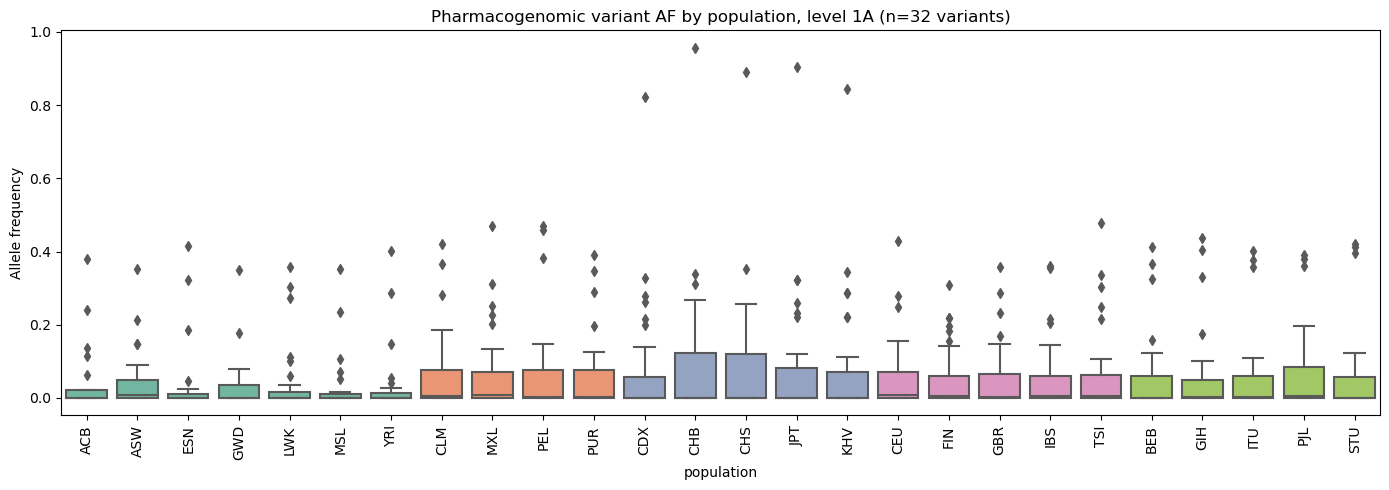

/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


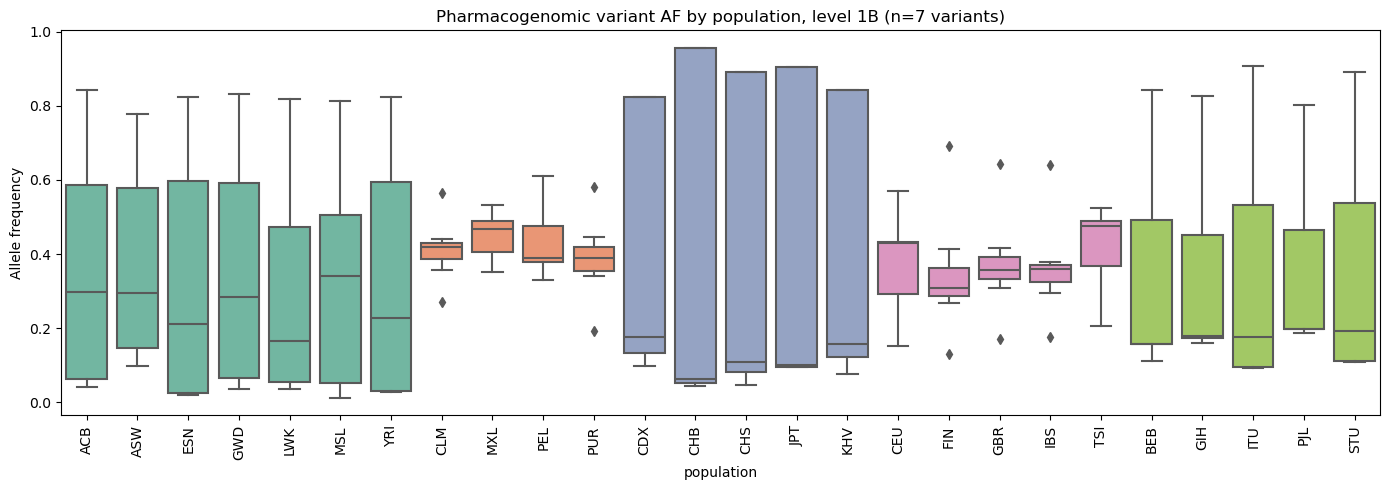

/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


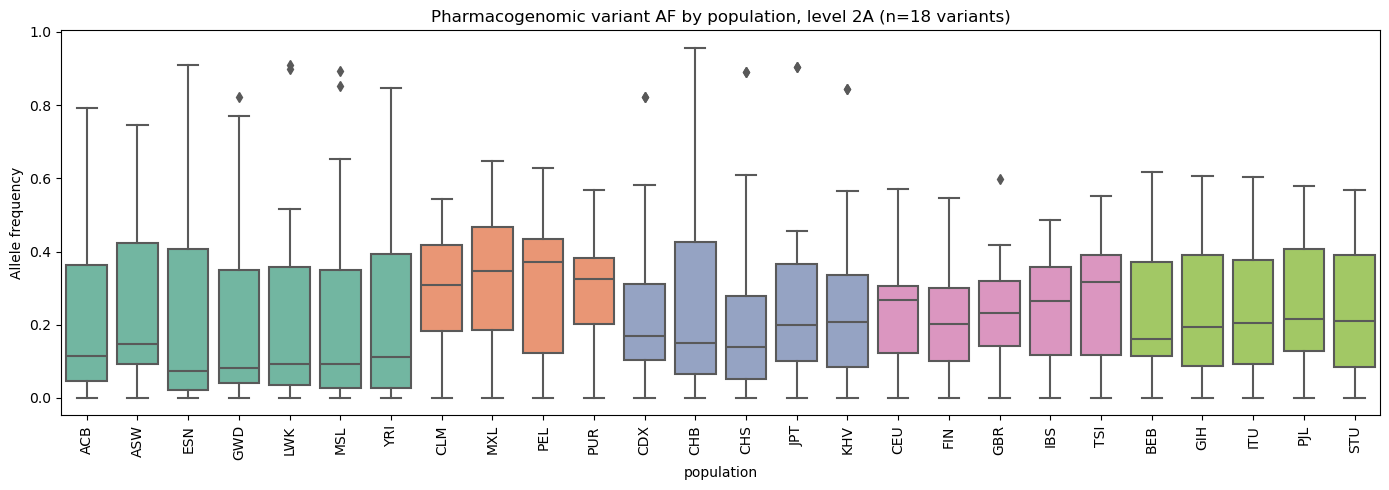

/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


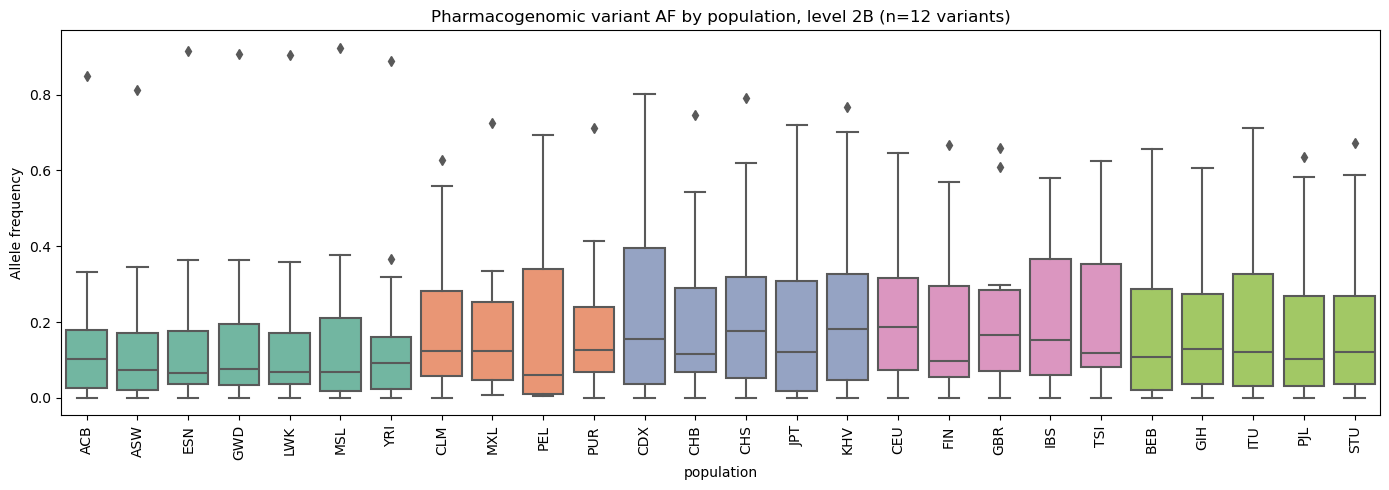

/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


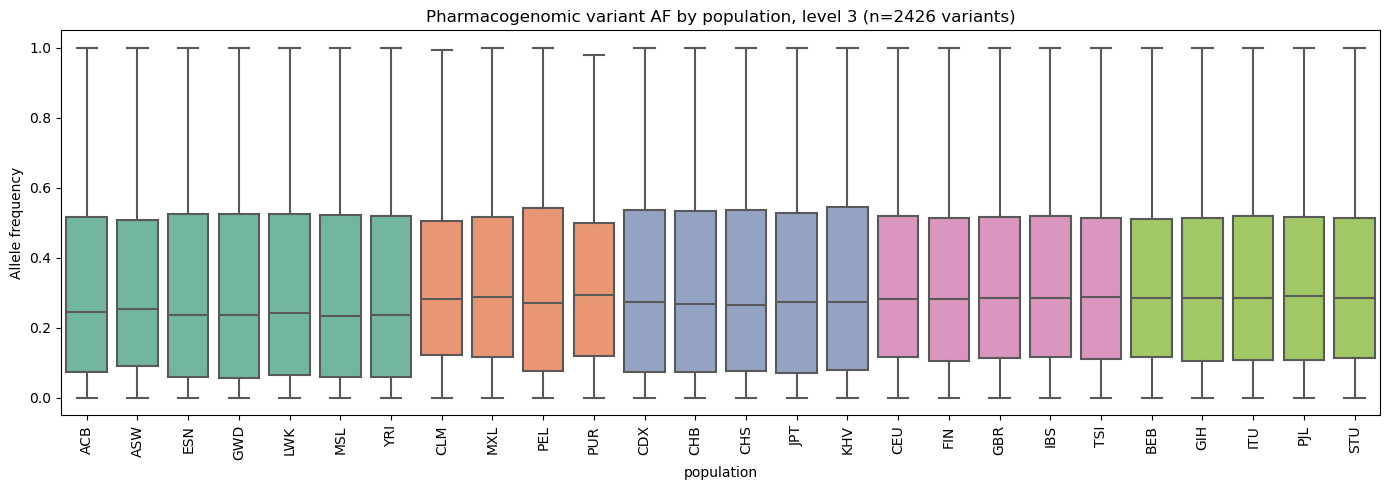

/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/storage/ice-shared/biol6150/SharedEnvironment/biol6150/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


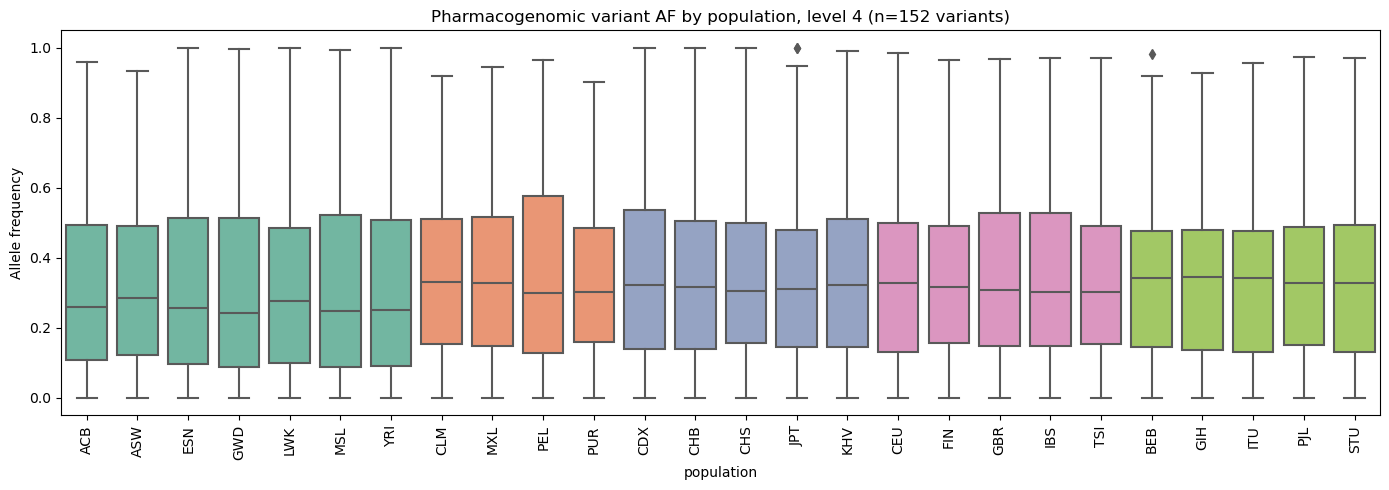

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

pan = pd.read_csv(panel_file, sep="\t")[["pop", "super_pop"]].drop_duplicates()
pop_order = pan.sort_values(["super_pop", "pop"])["pop"].tolist()
colors = dict(zip(sorted(pan["super_pop"].unique()), sns.color_palette("Set2", 5)))
pop_color = {p: colors[s] for p, s in zip(pan["pop"], pan["super_pop"])}

long = annot.melt(id_vars=["ID", "level"], value_vars=pop_cols,
                  var_name="population", value_name="AF")

for lvl in ["1A", "1B", "2A", "2B", "3", "4"]:
    sub = long[long["level"] == lvl]
    if sub.empty:
        continue
    plt.figure(figsize=(14, 5))
    sns.boxplot(data=sub, x="population", y="AF", order=pop_order, palette=pop_color)
    plt.title(f"Pharmacogenomic variant AF by population, level {lvl} (n={sub['ID'].nunique()} variants)")
    plt.xticks(rotation=90)
    plt.ylabel("Allele frequency")
    plt.tight_layout()
    plt.savefig(f"boxplot_level_{lvl}.png", dpi=200)
    plt.show()

<div class="alert alert-block alert-danger">
    <h2>Alert!</h2>
    <p>If you use R, please provide ample evidence of work.</p>
    <p>For R use, you should add appropriate screenshots and the R code here in this notebook as well. R code might not run for you on PACE-ICE Jupyter engine right now, but it will work for anyone replicating this work somehwere else (that anyone could be the "future you")</p>
</div>